# RL for Autonomous Navigation: Q-Learning, SARSA, DQN and PPO
### Dataset-driven 8 x 8 grid simulator (built from the Kaggle Autonomous Navigation Control Dataset)

**What is different from the earlier notebook:** the Kaggle driving dataset now sets two properties of the simulator, so it is no longer only inspected.

| Simulator property | Taken from the dataset | Assumption made by us |
|---|---|---|
| Obstacle density of the 8 x 8 map | Fraction of rows with `Distance_to_Obstacle_m` below a threshold | The threshold (15 m) |
| Slip noise (chance that an action is replaced by a random one) | Every episode samples one row of the dataset and uses the slip value of that row's `Weather_Condition` | The slip value per weather type (table in cell 3) |

The dataset has **no reward / next-state / done columns**, so it still cannot be used as logged RL data. Transitions and rewards are defined by our own rules. The correct description is therefore a **dataset-informed simulator**, not a simulator learned from data.

Run the cells from top to bottom. Set `QUICK_MODE = True` first to check that everything runs (about a minute), then set it to `False` for the real experiment.

In [ ]:
# ---------------- Cell 1: installs, imports, settings ----------------
import importlib, subprocess, sys
def ensure(pip_name, import_name=None):
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

ensure("gymnasium"); ensure("stable-baselines3", "stable_baselines3"); ensure("kagglehub")

import os, re, glob, time, json, random, warnings
from collections import deque
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.optim as optim
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
warnings.filterwarnings("ignore")

# ----------------------------- SETTINGS -----------------------------
QUICK_MODE = False                     # True = tiny debug run, False = full experiment
TRAIN_STEPS = 8_000 if QUICK_MODE else 60_000
SEEDS = [0] if QUICK_MODE else [0, 1, 2]
N_EVAL_EPISODES = 20 if QUICK_MODE else 100
GRID_SIZE = 8
MAX_EPISODE_STEPS = 100
MAP_SEED = 123
KAGGLE_DATASET = "freshersstaff/autonomous-navigation-control-dataset"
DATA_FILE = None                       # set a CSV path here to skip the Kaggle download
OBSTACLE_DIST_THRESHOLD_M = 15.0       # ASSUMPTION: an obstacle counts as "close" below this distance
USE_GPU_FOR_DEEP_RL = False
# ---------------------------------------------------------------------

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(42)
DEVICE = torch.device("cuda" if (torch.cuda.is_available() and USE_GPU_FOR_DEEP_RL) else "cpu")
print("torch", torch.__version__, "| gymnasium", gym.__version__, "| device:", DEVICE)
print(f"QUICK_MODE={QUICK_MODE}, TRAIN_STEPS={TRAIN_STEPS}, SEEDS={SEEDS}, N_EVAL_EPISODES={N_EVAL_EPISODES}")

Installing stable-baselines3 ...
torch 2.11.0+cu130 | gymnasium 1.4.0 | device: cpu
QUICK_MODE=False, TRAIN_STEPS=60000, SEEDS=[0, 1, 2], N_EVAL_EPISODES=100


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [ ]:
# ---------------- Cell 2: load the Kaggle driving dataset ----------------
if DATA_FILE:
    data_path = DATA_FILE
else:
    import kagglehub
    folder = kagglehub.dataset_download(KAGGLE_DATASET)
    files = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
    if not files: raise FileNotFoundError("No CSV found in the downloaded dataset.")
    data_path = max(files, key=os.path.getsize)
print("Using file:", data_path)

df = pd.read_csv(data_path).drop_duplicates().reset_index(drop=True)
print("Shape:", df.shape)
display(df.head())

def find_col(name_part):
    hits = [c for c in df.columns if name_part.lower() in c.lower()]
    if not hits: raise KeyError(f"No column containing '{name_part}'. Columns: {list(df.columns)}")
    return hits[0]

COL_DIST = find_col("distance_to_obstacle")
COL_WEATHER = find_col("weather")
print("Columns used:", COL_DIST, "|", COL_WEATHER)

100%|██████████| 64.0k/64.0k [00:00<00:00, 275kB/s]

Extracting files...


Using file: /root/.cache/kagglehub/datasets/freshersstaff/autonomous-navigation-control-dataset/versions/2/autonomous_navigation_dataset.csv
Shape: (1000, 16)


,Speed_kmph,Steering_Angle_deg,Distance_to_Obstacle_m,Traffic_Light_State,Pedestrian_Presence,Weather_Condition,Road_Type,Lane_Position,Camera_Input_Similarity,Lidar_Point_Cloud_Similarity,Distance_to_Intersection_m,Traffic_Sign_Detected,Steering_Command,Acceleration_Command,Steering_Command_Label,Acceleration_Command_Label
0,102,-22.738671,68.271226,Red,0,Snowy,Urban,1.778496,0.881976,0.855078,23.672446,1,1,1,Right,Accelerate
1,51,-4.451028,18.553116,Red,1,Rainy,Urban,2.170845,0.959084,0.431919,129.151836,0,1,1,Right,Accelerate
2,92,-33.375653,52.753757,Red,0,Snowy,Suburban,1.672097,0.192346,0.386099,50.016494,0,0,0,Straight,Maintain
3,14,40.864592,71.050103,Red,1,Rainy,Urban,1.673556,0.717373,0.689824,167.310478,1,1,1,Right,Accelerate
4,106,9.555717,11.134254,Green,0,Rainy,Suburban,2.687895,0.664339,0.602441,102.460072,0,1,1,Right,Accelerate


Columns used: Distance_to_Obstacle_m | Weather_Condition


In [ ]:
# ---------------- Cell 3: derive the simulator parameters from the dataset ----------------
# (a) Obstacle density: share of driving situations in which an obstacle is closer than the threshold.
raw_density = float((df[COL_DIST] < OBSTACLE_DIST_THRESHOLD_M).mean())
OBSTACLE_DENSITY = float(np.clip(raw_density, 0.05, 0.25))   # clipped so the grid stays solvable and not empty
print(f"Share of rows with {COL_DIST} < {OBSTACLE_DIST_THRESHOLD_M} m : {raw_density:.3f}")
print(f"Obstacle density used in the simulator              : {OBSTACLE_DENSITY:.3f}")

# (b) Slip noise from weather. The slip value per weather type is OUR ASSUMPTION (bad weather = less reliable control).
SLIP_BY_WEATHER = {"clear": 0.05, "sunny": 0.05, "cloudy": 0.07, "overcast": 0.07,
                   "rainy": 0.10, "rain": 0.10, "foggy": 0.12, "fog": 0.12,
                   "snowy": 0.15, "snow": 0.15}
DEFAULT_SLIP = 0.10
def slip_of(w):
    return SLIP_BY_WEATHER.get(str(w).strip().lower(), DEFAULT_SLIP)

weather_table = df[COL_WEATHER].value_counts().rename("rows").to_frame()
weather_table["share"] = (weather_table["rows"] / len(df)).round(3)
weather_table["slip_probability"] = [slip_of(w) for w in weather_table.index]
weather_table["mapped"] = ["yes" if str(w).strip().lower() in SLIP_BY_WEATHER else "NO (default used)" for w in weather_table.index]
display(weather_table)

# One slip value per dataset row. Each episode will sample one of them.
SLIP_VALUES = np.array([slip_of(w) for w in df[COL_WEATHER]], dtype=float)
print(f"Average slip probability over the dataset: {SLIP_VALUES.mean():.3f}")

Share of rows with Distance_to_Obstacle_m < 15.0 m : 0.155
Obstacle density used in the simulator              : 0.155


,rows,share,slip_probability,mapped
Weather_Condition,,,,
Snowy,268,0.268,0.15,yes
Foggy,252,0.252,0.12,yes
Rainy,248,0.248,0.10,yes
Sunny,232,0.232,0.05,yes


Average slip probability over the dataset: 0.107


Obstacle cells: 7 of 64
Obstacle positions (row, col): [(0, 1), (3, 1), (5, 0), (5, 6), (5, 7), (6, 2), (6, 4)]
First observation: [0. 0. 1. 1. 1. 0. 1. 1.] | slip this episode: 0.15


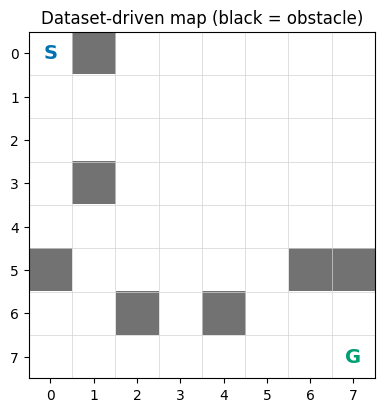

In [ ]:
# ---------------- Cell 4: the dataset-driven navigation environment ----------------
class NavigationEnv(gym.Env):
    ACTIONS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}      # up, down, left, right as (row, col)
    R_GOAL, R_COLLISION, R_WALL, R_STEP = 100.0, -50.0, -3.0, -1.0

    def __init__(self, grid_size=GRID_SIZE, obstacle_density=OBSTACLE_DENSITY, map_seed=MAP_SEED,
                 slip_values=SLIP_VALUES, slip_override=None, max_steps=MAX_EPISODE_STEPS):
        super().__init__()
        self.n, self.max_steps = grid_size, max_steps
        self.slip_values, self.slip_override = np.asarray(slip_values, float), slip_override
        self.start, self.goal = (0, 0), (grid_size - 1, grid_size - 1)
        self.obstacles = self._make_map(obstacle_density, map_seed)
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Box(low=-1.0, high=1.0, shape=(8,), dtype=np.float32)
        self.pos, self.steps, self.cur_slip = self.start, 0, 0.0

    def _solvable(self, obs):                                      # breadth-first search
        seen, queue = {self.start}, deque([self.start])
        while queue:
            r, c = queue.popleft()
            if (r, c) == self.goal: return True
            for dr, dc in self.ACTIONS.values():
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.n and 0 <= nc < self.n and not obs[nr, nc] and (nr, nc) not in seen:
                    seen.add((nr, nc)); queue.append((nr, nc))
        return False

    def _make_map(self, density, map_seed):
        rng = np.random.default_rng(map_seed)
        while True:
            obs = rng.random((self.n, self.n)) < density
            obs[self.start] = False; obs[self.goal] = False
            if self._solvable(obs): return obs

    def _blocked(self, r, c):
        return (not (0 <= r < self.n and 0 <= c < self.n)) or bool(self.obstacles[r, c])

    def _obs(self):
        r, c = self.pos; m = self.n - 1
        sensors = [float(self._blocked(r + dr, c + dc)) for dr, dc in self.ACTIONS.values()]
        return np.array([r / m, c / m, (self.goal[0] - r) / m, (self.goal[1] - c) / m] + sensors, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.pos, self.steps = self.start, 0
        # DATASET LINK: this episode's slip probability comes from a randomly drawn dataset row (its weather).
        self.cur_slip = self.slip_override if self.slip_override is not None else float(self.np_random.choice(self.slip_values))
        return self._obs(), {"slip": self.cur_slip}

    def step(self, action):
        if self.np_random.random() < self.cur_slip:
            action = int(self.np_random.integers(4))
        dr, dc = self.ACTIONS[int(action)]
        nr, nc = self.pos[0] + dr, self.pos[1] + dc
        reward, terminated, collision, success = self.R_STEP, False, False, False
        if not (0 <= nr < self.n and 0 <= nc < self.n):
            reward = self.R_WALL                                    # wall bump: stay in place
        elif self.obstacles[nr, nc]:
            reward, terminated, collision = self.R_COLLISION, True, True
        else:
            self.pos = (nr, nc)
            if self.pos == self.goal:
                reward, terminated, success = self.R_GOAL, True, True
        self.steps += 1
        truncated = (not terminated) and self.steps >= self.max_steps
        return self._obs(), reward, terminated, truncated, {"is_success": success, "collision": collision}

def make_env(**kw): return NavigationEnv(**kw)

def discretize(obs, n=GRID_SIZE):                                   # observation -> grid-cell id (for Q-tables)
    return int(round(float(obs[0]) * (n - 1))) * n + int(round(float(obs[1]) * (n - 1)))

env_demo = make_env()
print("Obstacle cells:", int(env_demo.obstacles.sum()), "of", GRID_SIZE * GRID_SIZE)
print("Obstacle positions (row, col):", [tuple(map(int, x)) for x in np.argwhere(env_demo.obstacles)])
o, info = env_demo.reset(seed=0)
print("First observation:", np.round(o, 2), "| slip this episode:", info["slip"])

def draw_map(ax, env, title, path=None):
    ax.imshow(np.where(env.obstacles, 1.0, 0.0), cmap="Greys", vmin=0, vmax=1.6)
    ax.text(env.start[1], env.start[0], "S", ha="center", va="center", color="#0072B2", fontsize=14, fontweight="bold")
    ax.text(env.goal[1], env.goal[0], "G", ha="center", va="center", color="#009E73", fontsize=14, fontweight="bold")
    if path: ax.plot([p[1] for p in path], [p[0] for p in path], "-o", color="#D55E00", ms=4, lw=2)
    ax.set_xticks(range(env.n)); ax.set_yticks(range(env.n)); ax.set_title(title)
    ax.set_xticks(np.arange(-.5, env.n, 1), minor=True); ax.set_yticks(np.arange(-.5, env.n, 1), minor=True)
    ax.grid(which="minor", color="lightgray", lw=0.5); ax.tick_params(which="minor", length=0)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_map(ax, env_demo, "Dataset-driven map (black = obstacle)"); plt.show()

In [ ]:
# ---------------- Cell 5: shared training / evaluation utilities ----------------
GAMMA = 0.99
EPS_START, EPS_END, EPS_FRACTION = 1.0, 0.05, 0.6

def epsilon_at(step, total=TRAIN_STEPS):
    return EPS_START + min(1.0, step / (EPS_FRACTION * total)) * (EPS_END - EPS_START)

def new_log(): return {"end_step": [], "reward": [], "success": [], "collision": [], "length": []}

def add_episode(log, step, ep_reward, info, length):
    log["end_step"].append(step); log["reward"].append(ep_reward)
    log["success"].append(int(info.get("is_success", False)))
    log["collision"].append(int(info.get("collision", False))); log["length"].append(length)

class GreedyAgent:
    def __init__(self, act_fn): self.act = act_fn

def evaluate(agent, n_episodes=N_EVAL_EPISODES, seed_base=10_000):
    # Greedy evaluation on fixed seeds. Slip is still sampled from the dataset's weather mix.
    env, rows = make_env(), []
    for i in range(n_episodes):
        obs, _ = env.reset(seed=seed_base + i)
        done, total, steps, info = False, 0.0, 0, {}
        while not done:
            obs, r, term, trunc, info = env.step(agent.act(obs))
            total += r; steps += 1; done = term or trunc
        rows.append({"reward": total, "success": int(info["is_success"]),
                     "collision": int(info["collision"]), "steps": steps})
    d = pd.DataFrame(rows)
    return {"avg_reward": d.reward.mean(), "success_rate": d.success.mean(),
            "avg_steps_to_goal": d.steps[d.success == 1].mean() if d.success.sum() else np.nan,
            "collision_rate": d.collision.mean(),
            "timeout_rate": 1 - d.success.mean() - d.collision.mean()}
print("Shared tools ready.")

Shared tools ready.


In [ ]:
# ---------------- Cell 6: Q-Learning and SARSA (tabular) ----------------
ALPHA = 0.1
N_STATES, N_ACTIONS = GRID_SIZE * GRID_SIZE, 4

def train_tabular(algo, seed, total_steps=TRAIN_STEPS):
    rng = np.random.default_rng(seed)
    Q = np.zeros((N_STATES, N_ACTIONS))
    env, log = make_env(), new_log()
    def choose(s, step):
        if rng.random() < epsilon_at(step, total_steps): return int(rng.integers(N_ACTIONS))
        return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))       # random tie-breaking
    step, first = 0, True
    while step < total_steps:
        obs, _ = env.reset(seed=seed if first else None); first = False
        s = discretize(obs); a = choose(s, step)
        ep_r, ep_len, done, info = 0.0, 0, False, {}
        while not done and step < total_steps:
            obs2, r, term, trunc, info = env.step(a); step += 1
            s2 = discretize(obs2); a2 = choose(s2, step)
            if term: target = r
            elif algo == "qlearning": target = r + GAMMA * Q[s2].max()      # off-policy
            else: target = r + GAMMA * Q[s2, a2]                            # SARSA, on-policy
            Q[s, a] += ALPHA * (target - Q[s, a])
            s, a = s2, a2; ep_r += r; ep_len += 1; done = term or trunc
            if done: add_episode(log, step, ep_r, info, ep_len)
    return GreedyAgent(lambda o: int(Q[discretize(o)].argmax())), log

_a, _l = train_tabular("qlearning", seed=0, total_steps=500)
print("Sanity check OK - episodes logged:", len(_l["reward"]))

Sanity check OK - episodes logged: 39


In [ ]:
# ---------------- Cell 7: DQN ----------------
class QNetwork(nn.Module):
    def __init__(self, n_in=8, n_out=4, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, n_out))
    def forward(self, x): return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity=20_000, obs_dim=8):
        self.cap, self.i, self.size = capacity, 0, 0
        self.s = np.zeros((capacity, obs_dim), np.float32); self.s2 = np.zeros((capacity, obs_dim), np.float32)
        self.a = np.zeros(capacity, np.int64); self.r = np.zeros(capacity, np.float32); self.term = np.zeros(capacity, np.float32)
    def add(self, s, a, r, s2, term):
        self.s[self.i], self.a[self.i], self.r[self.i], self.s2[self.i], self.term[self.i] = s, a, r, s2, float(term)
        self.i = (self.i + 1) % self.cap; self.size = min(self.size + 1, self.cap)
    def sample(self, batch, rng):
        idx = rng.integers(0, self.size, size=batch)
        t = lambda x: torch.as_tensor(x[idx], device=DEVICE)
        return t(self.s), t(self.a), t(self.r), t(self.s2), t(self.term)

DQN_LR, DQN_BATCH, DQN_LEARN_START, DQN_TARGET_EVERY = 1e-3, 64, 500, 250

def train_dqn(seed, total_steps=TRAIN_STEPS):
    set_seed(seed); rng = np.random.default_rng(seed)
    q, q_target = QNetwork().to(DEVICE), QNetwork().to(DEVICE)
    q_target.load_state_dict(q.state_dict())
    opt, buf, loss_fn = optim.Adam(q.parameters(), lr=DQN_LR), ReplayBuffer(), nn.SmoothL1Loss()
    env, log = make_env(), new_log()
    def greedy(o):
        with torch.no_grad():
            return int(q(torch.as_tensor(o, dtype=torch.float32, device=DEVICE).unsqueeze(0)).argmax(1).item())
    step, first = 0, True
    while step < total_steps:
        obs, _ = env.reset(seed=seed if first else None); first = False
        ep_r, ep_len, done, info = 0.0, 0, False, {}
        while not done and step < total_steps:
            a = int(rng.integers(4)) if rng.random() < epsilon_at(step, total_steps) else greedy(obs)
            obs2, r, term, trunc, info = env.step(a); step += 1
            buf.add(obs, a, r, obs2, term)                                   # only true termination stops bootstrapping
            obs, ep_r, ep_len, done = obs2, ep_r + r, ep_len + 1, term or trunc
            if step >= DQN_LEARN_START and buf.size >= DQN_BATCH:
                s, a_b, r_b, s2, t_b = buf.sample(DQN_BATCH, rng)
                q_sa = q(s).gather(1, a_b.unsqueeze(1)).squeeze(1)
                with torch.no_grad():
                    y = r_b + GAMMA * (1 - t_b) * q_target(s2).max(1)[0]
                loss = loss_fn(q_sa, y)
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(q.parameters(), 10.0); opt.step()
            if step % DQN_TARGET_EVERY == 0: q_target.load_state_dict(q.state_dict())
            if done: add_episode(log, step, ep_r, info, ep_len)
    return GreedyAgent(greedy), log

_a, _l = train_dqn(seed=0, total_steps=1000)
print("Sanity check OK - episodes logged:", len(_l["reward"]))

Sanity check OK - episodes logged: 86


In [ ]:
# ---------------- Cell 8: PPO (Stable-Baselines3) ----------------
class EpisodeLogger(BaseCallback):
    def __init__(self):
        super().__init__(); self.log, self.ep_r, self.ep_len = new_log(), 0.0, 0
    def _on_step(self):
        self.ep_r += float(self.locals["rewards"][0]); self.ep_len += 1
        if bool(self.locals["dones"][0]):
            add_episode(self.log, self.num_timesteps, self.ep_r, self.locals["infos"][0], self.ep_len)
            self.ep_r, self.ep_len = 0.0, 0
        return True

PPO_N_STEPS, PPO_BATCH = 500, 100

def train_ppo(seed, total_steps=TRAIN_STEPS):
    set_seed(seed)
    env = make_env()
    model = PPO("MlpPolicy", env, n_steps=PPO_N_STEPS, batch_size=PPO_BATCH, n_epochs=10,
                learning_rate=3e-4, gamma=GAMMA, gae_lambda=0.95, clip_range=0.2, ent_coef=0.01,
                policy_kwargs=dict(net_arch=[64, 64]), seed=seed, device=str(DEVICE), verbose=0)
    cb = EpisodeLogger()
    model.learn(total_timesteps=total_steps, callback=cb)
    return GreedyAgent(lambda o: int(model.predict(o, deterministic=True)[0])), cb.log

_a, _l = train_ppo(seed=0, total_steps=1000)
print("Sanity check OK - episodes logged:", len(_l["reward"]))

Sanity check OK - episodes logged: 141


In [ ]:
# ---------------- Cell 9: train all 4 algorithms x all seeds ----------------
ALGOS = {"Q-Learning": lambda s: train_tabular("qlearning", s),
         "SARSA":      lambda s: train_tabular("sarsa", s),
         "DQN":        lambda s: train_dqn(s),
         "PPO":        lambda s: train_ppo(s)}
results, agents = {a: {} for a in ALGOS}, {a: {} for a in ALGOS}
for name, fn in ALGOS.items():
    for seed in SEEDS:
        t0 = time.time()
        agent, log = fn(seed)
        results[name][seed] = {"log": log, "train_time": time.time() - t0}
        agents[name][seed] = agent
        print(f"{name:10s} seed {seed}: {len(log['reward']):5d} episodes, {results[name][seed]['train_time']:6.1f}s")

Q-Learning seed 0:  4306 episodes,    2.3s
Q-Learning seed 1:  3932 episodes,    2.0s
Q-Learning seed 2:  3977 episodes,    2.0s
SARSA      seed 0:  3687 episodes,    1.9s
SARSA      seed 1:  3750 episodes,    1.9s
SARSA      seed 2:  3669 episodes,    2.7s
DQN        seed 0:  4424 episodes,  133.1s
DQN        seed 1:  4490 episodes,  135.3s
DQN        seed 2:  4440 episodes,  129.4s
PPO        seed 0: 28841 episodes,   70.3s
PPO        seed 1: 26242 episodes,   69.3s
PPO        seed 2:  4230 episodes,   69.6s


In [ ]:
# ---------------- Cell 10: evaluation and metrics ----------------
def moving_avg(x, w):
    x = np.asarray(x, dtype=float)
    if len(x) == 0: return x
    w = min(w, len(x)); return np.convolve(x, np.ones(w) / w, mode="valid")

def convergence_step(log, window=50, thresh=0.8):
    ma = moving_avg(log["success"], window)
    idx = np.flatnonzero(ma >= thresh)
    return np.nan if len(idx) == 0 else log["end_step"][idx[0] + min(window, len(log["success"])) - 1]

def stability(log):
    r = [x for x, s in zip(log["reward"], log["end_step"]) if s >= 0.8 * TRAIN_STEPS]
    return float(np.std(r)) if len(r) > 1 else np.nan

for name in ALGOS:
    for seed in SEEDS:
        res = results[name][seed]
        res["eval"] = evaluate(agents[name][seed])
        res["convergence_step"] = convergence_step(res["log"])
        res["stability_std"] = stability(res["log"])

rows = []
for name in ALGOS:
    for seed in SEEDS:
        r = results[name][seed]
        rows.append({"algorithm": name, "seed": seed, **r["eval"], "convergence_step": r["convergence_step"],
                     "stability_std": r["stability_std"], "train_time_s": r["train_time"]})
per_seed = pd.DataFrame(rows)
print("Per-seed results:")
display(per_seed.round(3))

Per-seed results:


,algorithm,seed,avg_reward,success_rate,avg_steps_to_goal,collision_rate,timeout_rate,convergence_step,stability_std,train_time_s
0,Q-Learning,0,-93.35,0.02,58.000,0.16,0.82,39629.0,65.261,2.274
1,Q-Learning,1,63.32,0.85,15.835,0.15,0.00,34651.0,63.755,1.984
2,Q-Learning,2,65.93,0.87,16.000,0.13,0.00,34880.0,63.342,2.003
3,SARSA,0,64.54,0.86,15.860,0.14,0.00,31699.0,52.897,1.852
4,SARSA,1,63.42,0.85,15.718,0.15,0.00,34683.0,57.313,1.855
5,SARSA,2,32.32,0.77,34.584,0.14,0.09,31860.0,56.990,2.671
6,DQN,0,60.59,0.83,15.602,0.17,0.00,40413.0,60.889,133.069
7,DQN,1,58.86,0.82,15.463,0.18,0.00,41175.0,61.431,135.299
8,DQN,2,53.61,0.78,15.551,0.22,-0.00,36454.0,63.385,129.429
9,PPO,0,-50.37,0.00,NaN,1.00,0.00,NaN,1.091,70.277


In [ ]:
# ---------------- Cell 11: comparison table (mean +/- std over seeds) ----------------
def pm(series, d=2):
    s = series.dropna()
    return "n/a" if len(s) == 0 else f"{s.mean():.{d}f} ± {s.std(ddof=0):.{d}f}"

table = []
for name in ALGOS:
    d = per_seed[per_seed.algorithm == name]
    table.append({"Algorithm": name, "Avg reward": pm(d.avg_reward, 1), "Success rate": pm(d.success_rate, 3),
                  "Avg steps to goal": pm(d.avg_steps_to_goal, 1), "Collision rate": pm(d.collision_rate, 3),
                  "Convergence step": pm(d.convergence_step, 0) + f" ({int(d.convergence_step.notna().sum())}/{len(d)} seeds)",
                  "Stability (reward std)": pm(d.stability_std, 1), "Train time (s)": pm(d.train_time_s, 1)})
comparison = pd.DataFrame(table).set_index("Algorithm")
display(comparison)

means = per_seed.groupby("algorithm")[["avg_reward", "success_rate", "avg_steps_to_goal", "collision_rate",
                                       "convergence_step", "stability_std", "train_time_s"]].mean()
medians = per_seed.groupby("algorithm")[["success_rate", "avg_reward"]].median()
print("\nMedian over seeds (less affected by one bad seed):")
display(medians.round(3))

os.makedirs("outputs", exist_ok=True)
per_seed.to_csv("outputs/per_seed_results.csv", index=False)
means.to_csv("outputs/mean_results.csv")
with open("outputs/training_logs.json", "w") as f:
    json.dump({a: {str(s): results[a][s]["log"] for s in SEEDS} for a in ALGOS}, f)
print("Saved to outputs/: per_seed_results.csv, mean_results.csv, training_logs.json")

,Avg reward,Success rate,Avg steps to goal,Collision rate,Convergence step,Stability (reward std),Train time (s)
Algorithm,,,,,,,
Q-Learning,12.0 ± 74.5,0.580 ± 0.396,29.9 ± 19.8,0.147 ± 0.012,36387 ± 2295 (3/3 seeds),64.1 ± 0.8,2.1 ± 0.1
SARSA,53.4 ± 14.9,0.827 ± 0.040,22.1 ± 8.9,0.143 ± 0.005,32747 ± 1370 (3/3 seeds),55.7 ± 2.0,2.1 ± 0.4
DQN,57.7 ± 3.0,0.810 ± 0.022,15.5 ± 0.1,0.190 ± 0.022,39347 ± 2069 (3/3 seeds),61.9 ± 1.1,132.6 ± 2.4
PPO,-16.2 ± 48.3,0.257 ± 0.363,15.5 ± 0.0,0.743 ± 0.363,16836 ± 0 (1/3 seeds),18.8 ± 25.1,69.7 ± 0.4



Median over seeds (less affected by one bad seed):


,success_rate,avg_reward
algorithm,,
DQN,0.82,58.86
PPO,0.00,-50.37
Q-Learning,0.85,63.32
SARSA,0.85,63.42


Saved to outputs/: per_seed_results.csv, mean_results.csv, training_logs.json


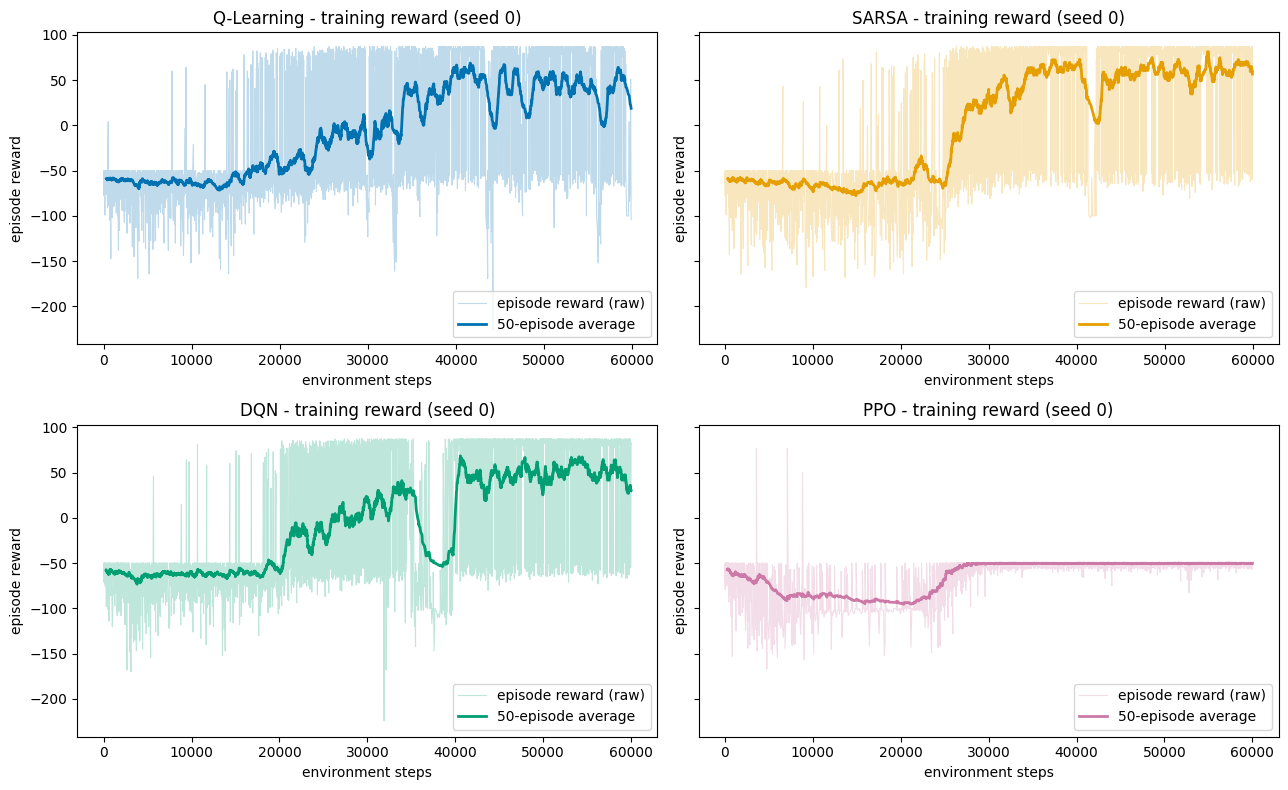

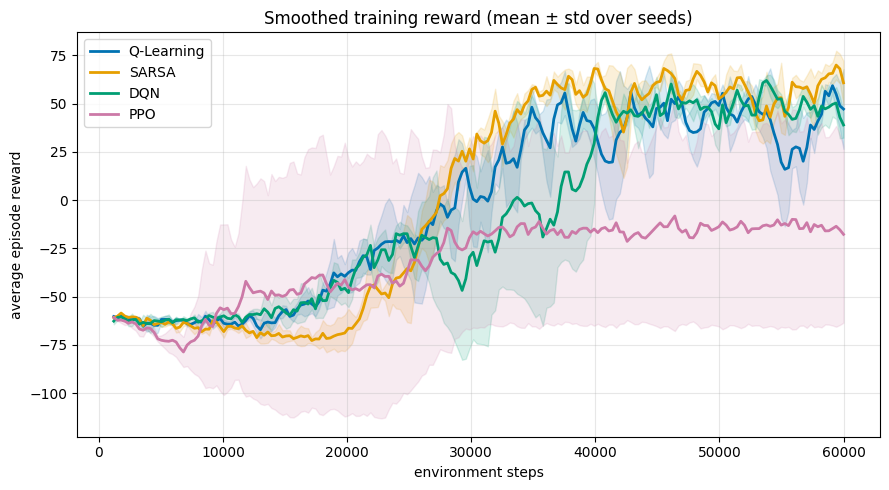

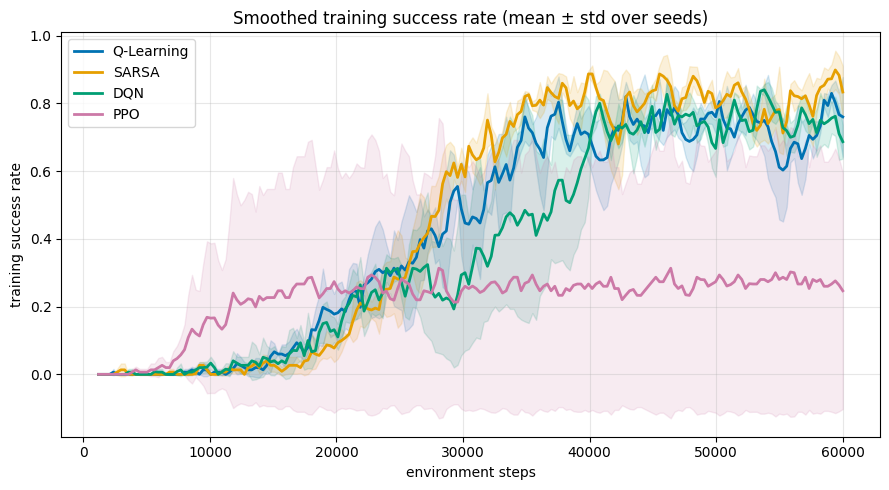

Note: training curves include exploration, so they lie below the greedy evaluation results.


In [ ]:
# ---------------- Cell 12: training curves ----------------
COLORS = {"Q-Learning": "#0072B2", "SARSA": "#E69F00", "DQN": "#009E73", "PPO": "#CC79A7"}
WINDOW = 50
seed0 = SEEDS[0]
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, name in zip(axes.ravel(), ALGOS):
    lg = results[name][seed0]["log"]
    ax.plot(lg["end_step"], lg["reward"], color=COLORS[name], alpha=0.25, lw=0.8, label="episode reward (raw)")
    ma = moving_avg(lg["reward"], WINDOW)
    ax.plot(lg["end_step"][len(lg["end_step"]) - len(ma):], ma, color=COLORS[name], lw=2, label=f"{WINDOW}-episode average")
    ax.set_title(f"{name} - training reward (seed {seed0})")
    ax.set_xlabel("environment steps"); ax.set_ylabel("episode reward"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

grid = np.linspace(TRAIN_STEPS * 0.02, TRAIN_STEPS, 200)
def curve_on_grid(log, key):
    ma = moving_avg(log[key], WINDOW)
    xs = np.asarray(log["end_step"][len(log["end_step"]) - len(ma):], dtype=float)
    return np.interp(grid, xs, ma) if len(xs) > 1 else np.full_like(grid, np.nan)

for key, ylabel, title in [("reward", "average episode reward", "Smoothed training reward (mean ± std over seeds)"),
                           ("success", "training success rate", "Smoothed training success rate (mean ± std over seeds)")]:
    plt.figure(figsize=(9, 5))
    for name in ALGOS:
        cs = np.array([curve_on_grid(results[name][s]["log"], key) for s in SEEDS])
        m, sd = np.nanmean(cs, 0), np.nanstd(cs, 0)
        plt.plot(grid, m, color=COLORS[name], lw=2, label=name)
        plt.fill_between(grid, m - sd, m + sd, color=COLORS[name], alpha=0.15)
    plt.xlabel("environment steps"); plt.ylabel(ylabel); plt.title(title)
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("Note: training curves include exploration, so they lie below the greedy evaluation results.")

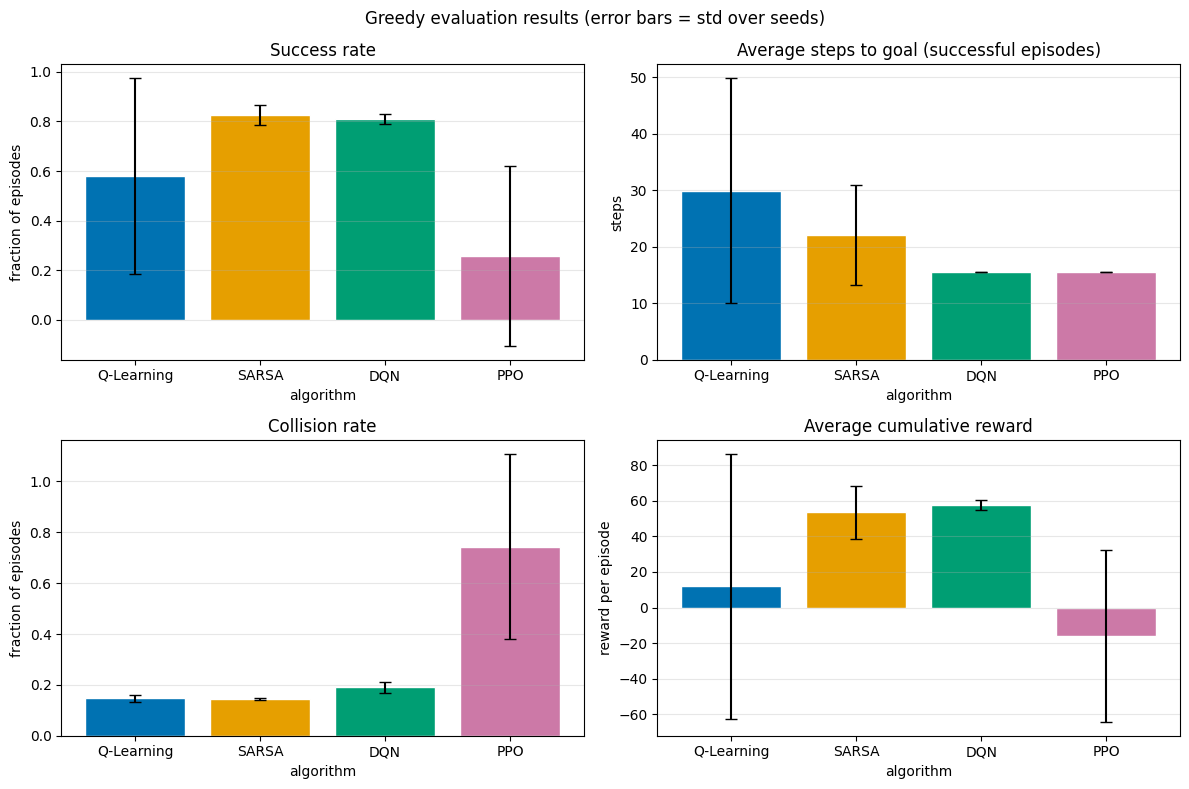

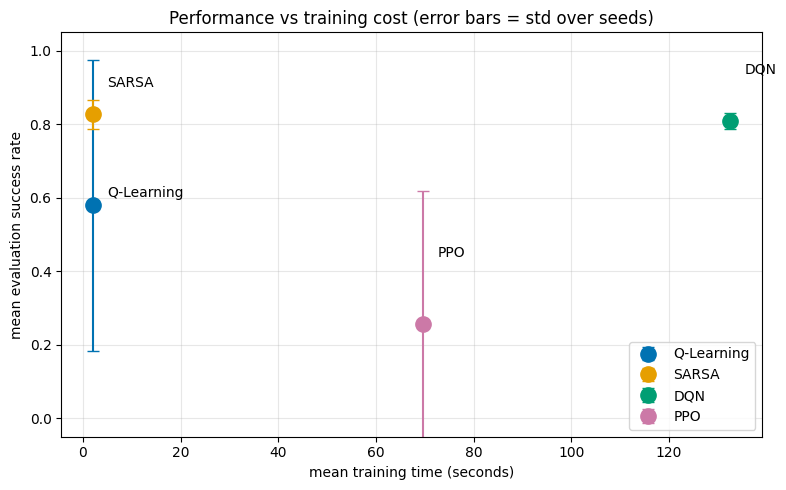

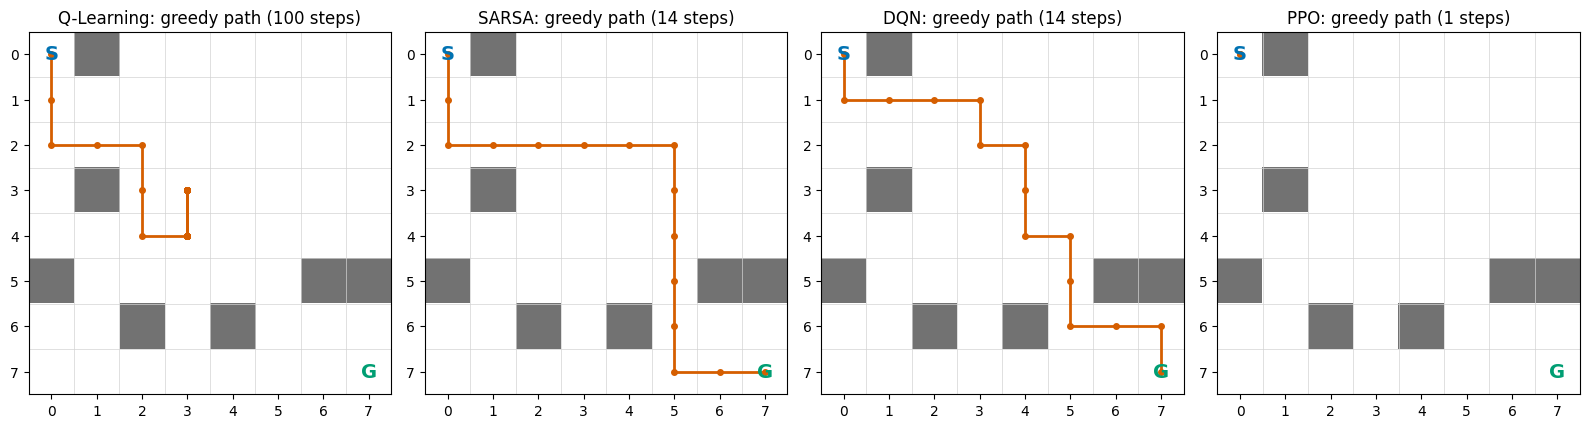

In [ ]:
# ---------------- Cell 13: bar charts, cost plot and greedy paths ----------------
metrics = [("success_rate", "Success rate", "fraction of episodes"),
           ("avg_steps_to_goal", "Average steps to goal (successful episodes)", "steps"),
           ("collision_rate", "Collision rate", "fraction of episodes"),
           ("avg_reward", "Average cumulative reward", "reward per episode")]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title, yl) in zip(axes.ravel(), metrics):
    g = per_seed.groupby("algorithm")[col]
    m = g.mean().reindex(list(ALGOS)); sd = g.std(ddof=0).reindex(list(ALGOS))
    ax.bar(m.index, m.values, yerr=sd.values, capsize=4, color=[COLORS[a] for a in m.index], edgecolor="white")
    ax.set_title(title); ax.set_ylabel(yl); ax.set_xlabel("algorithm"); ax.grid(axis="y", alpha=0.3)
plt.suptitle("Greedy evaluation results (error bars = std over seeds)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for i, name in enumerate(ALGOS):
    d = per_seed[per_seed.algorithm == name]
    ax.errorbar(d.train_time_s.mean(), d.success_rate.mean(), yerr=d.success_rate.std(ddof=0), fmt="o", ms=11,
                color=COLORS[name], capsize=4, label=name)
    ax.annotate(name, (d.train_time_s.mean(), d.success_rate.mean()), textcoords="offset points", xytext=(10, 6 + 14 * i))
ax.set_xlabel("mean training time (seconds)"); ax.set_ylabel("mean evaluation success rate")
ax.set_ylim(-0.05, 1.05); ax.set_title("Performance vs training cost (error bars = std over seeds)")
ax.grid(alpha=0.3); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

# Greedy paths of the seed-0 agents (slip switched OFF only for this illustration)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, name in zip(axes, ALGOS):
    e = make_env(slip_override=0.0); o, _ = e.reset(seed=0); path = [e.pos]; done = False
    while not done:
        o, _, te, tr, _ = e.step(agents[name][seed0].act(o)); path.append(e.pos); done = te or tr
    draw_map(ax, e, f"{name}: greedy path ({len(path)-1} steps)", path)
plt.tight_layout(); plt.show()

In [ ]:
# ---------------- Cell 14: ranking and honest summary ----------------
ranking = means.sort_values(["success_rate", "avg_reward", "collision_rate"], ascending=[False, False, True])
best = ranking.index[0]
rank_table = ranking[["success_rate", "avg_reward", "collision_rate", "avg_steps_to_goal", "train_time_s"]].round(3)
rank_table.insert(0, "rank", range(1, len(rank_table) + 1))
display(rank_table)

sd = per_seed.groupby("algorithm").success_rate.std(ddof=0)
second = ranking.index[1]
gap = ranking.loc[best, "success_rate"] - ranking.loc[second, "success_rate"]
print(f"Best by mean success rate: {best}. Lead over {second}: {gap:.3f} (seed std: {sd[best]:.3f} vs {sd[second]:.3f})")
print("-> the lead is", "larger than" if gap > max(sd[best], sd[second]) else "NOT clearly larger than",
      "the seed-to-seed variation; with", len(SEEDS), "seed(s) treat this as indicative, not proof.")
print(f"Cheapest to train: {means.train_time_s.idxmin()} ({means.train_time_s.min():.0f}s); "
      f"most expensive: {means.train_time_s.idxmax()} ({means.train_time_s.max():.0f}s).")
print("\nSimulator parameters that came from the Kaggle dataset:")
print(f"  obstacle density = {OBSTACLE_DENSITY:.3f}  (share of rows with {COL_DIST} < {OBSTACLE_DIST_THRESHOLD_M} m)")
print(f"  slip probability = sampled per episode from dataset weather, mean {SLIP_VALUES.mean():.3f}")
if QUICK_MODE: print("\nWARNING: QUICK_MODE is on - do not draw conclusions from these numbers.")
print("All results come from a SIMULATED environment, not a real vehicle.")

,rank,success_rate,avg_reward,collision_rate,avg_steps_to_goal,train_time_s
algorithm,,,,,,
SARSA,1,0.827,53.427,0.143,22.054,2.126
DQN,2,0.810,57.687,0.190,15.539,132.599
Q-Learning,3,0.580,11.967,0.147,29.945,2.087
PPO,4,0.257,-16.197,0.743,15.494,69.722


Best by mean success rate: SARSA. Lead over DQN: 0.017 (seed std: 0.040 vs 0.022)
-> the lead is NOT clearly larger than the seed-to-seed variation; with 3 seed(s) treat this as indicative, not proof.
Cheapest to train: Q-Learning (2s); most expensive: DQN (133s).

Simulator parameters that came from the Kaggle dataset:
  obstacle density = 0.155  (share of rows with Distance_to_Obstacle_m < 15.0 m)
  slip probability = sampled per episode from dataset weather, mean 0.107
All results come from a SIMULATED environment, not a real vehicle.


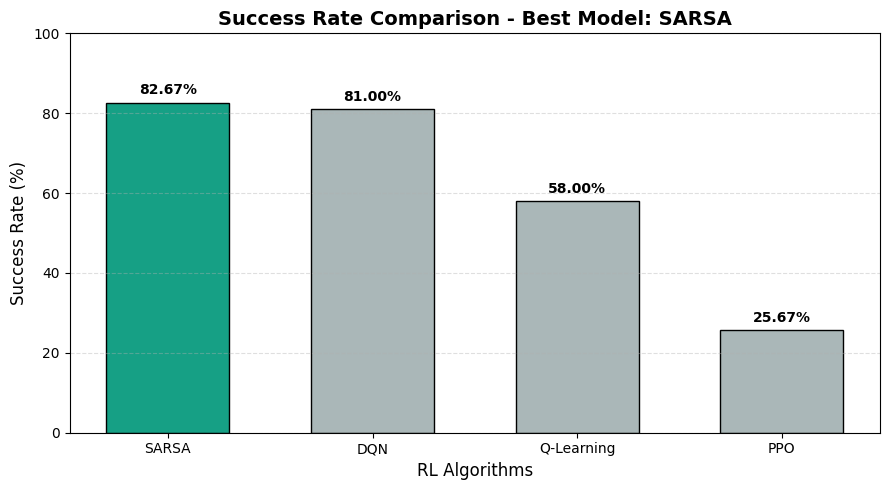

Highest Success Rate Model: SARSA
Success Rate: 82.67%


In [18]:
# ---------------- Success Rate Comparison - Highlight Best Model ----------------

import matplotlib.pyplot as plt

success_rates = ranking["success_rate"].copy()

# Convert to percentage if values are between 0 and 1
if success_rates.max() <= 1:
    success_rates = success_rates * 100

# Identify the best model
best_model = success_rates.idxmax()

# Highlight best model
colors = [
    "#16A085" if model == best_model else "#AAB7B8"
    for model in success_rates.index
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    success_rates.index.astype(str),
    success_rates.values,
    color=colors,
    edgecolor="black",
    width=0.6
)

plt.title(
    f"Success Rate Comparison - Best Model: {best_model}",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("RL Algorithms", fontsize=12)
plt.ylabel("Success Rate (%)", fontsize=12)

plt.ylim(0, 100)

plt.bar_label(
    bars,
    labels=[f"{v:.2f}%" for v in success_rates.values],
    padding=4,
    fontweight="bold"
)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Highest Success Rate Model: {best_model}")
print(f"Success Rate: {success_rates[best_model]:.2f}%")